In [1]:
# Data manipulation
import numpy as np
import pandas as pd

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Dataset
from sklearn.datasets import fetch_california_housing

# Train-test split
from sklearn.model_selection import train_test_split

# Machine learning model
from sklearn.linear_model import LinearRegression

# Model evaluation
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Display settings
pd.set_option("display.max_columns", None)

# Visualization style
sns.set_theme(style="whitegrid")

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
housing = fetch_california_housing(as_frame=True)

df = housing.frame

print("Dataset Loaded Successfully!")

print("Dataset Shape:", df.shape)

display(df.head())

Dataset Loaded Successfully!
Dataset Shape: (20640, 9)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [4]:
print("Dataset Information")
print("===================")

print("\nNumber of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Data Types:")
print(df.dtypes)

print("\nDataset Information:")
df.info()

Dataset Information

Number of Rows: 20640
Number of Columns: 9

Column Names:
['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude', 'MedHouseVal']

Dataset Data Types:
MedInc         float64
HouseAge       float64
AveRooms       float64
AveBedrms      float64
Population     float64
AveOccup       float64
Latitude       float64
Longitude      float64
MedHouseVal    float64
dtype: object

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVa

In [5]:
print("Statistical Summary")
print("===================")

display(df.describe().T)

Statistical Summary


,count,mean,std,min,25%,50%,75%,max
MedInc,20640.0,3.870671,1.899822,0.499900,2.563400,3.534800,4.743250,15.000100
HouseAge,20640.0,28.639486,12.585558,1.000000,18.000000,29.000000,37.000000,52.000000
AveRooms,20640.0,5.429000,2.474173,0.846154,4.440716,5.229129,6.052381,141.909091
AveBedrms,20640.0,1.096675,0.473911,0.333333,1.006079,1.048780,1.099526,34.066667
Population,20640.0,1425.476744,1132.462122,3.000000,787.000000,1166.000000,1725.000000,35682.000000
AveOccup,20640.0,3.070655,10.386050,0.692308,2.429741,2.818116,3.282261,1243.333333
Latitude,20640.0,35.631861,2.135952,32.540000,33.930000,34.260000,37.710000,41.950000
Longitude,20640.0,-119.569704,2.003532,-124.350000,-121.800000,-118.490000,-118.010000,-114.310000
MedHouseVal,20640.0,2.068558,1.153956,0.149990,1.196000,1.797000,2.647250,5.000010


In [6]:
print("Missing Values Analysis")
print("=======================")

missing_values = df.isnull().sum()

missing_percentage = (
    df.isnull().mean() * 100
)

missing_summary = pd.DataFrame({
    "Missing Values": missing_values,
    "Missing Percentage": missing_percentage
})

display(missing_summary)

Missing Values Analysis


,Missing Values,Missing Percentage
MedInc,0,0.0
HouseAge,0,0.0
AveRooms,0,0.0
AveBedrms,0,0.0
Population,0,0.0
AveOccup,0,0.0
Latitude,0,0.0
Longitude,0,0.0
MedHouseVal,0,0.0


In [7]:
print("Duplicate Records Analysis")
print("==========================")

duplicate_count = df.duplicated().sum()

print("Total Duplicate Rows:", duplicate_count)

print(
    "Duplicate Percentage:",
    round((duplicate_count / len(df)) * 100, 2),
    "%"
)

Duplicate Records Analysis
Total Duplicate Rows: 0
Duplicate Percentage: 0.0 %


In [8]:
print("Unique Values Analysis")
print("======================")

for column in df.columns:
    print(
        f"{column}: {df[column].nunique()} unique values"
    )

Unique Values Analysis
MedInc: 12928 unique values
HouseAge: 52 unique values
AveRooms: 19392 unique values
AveBedrms: 14233 unique values
Population: 3888 unique values
AveOccup: 18841 unique values
Latitude: 862 unique values
Longitude: 844 unique values
MedHouseVal: 3842 unique values


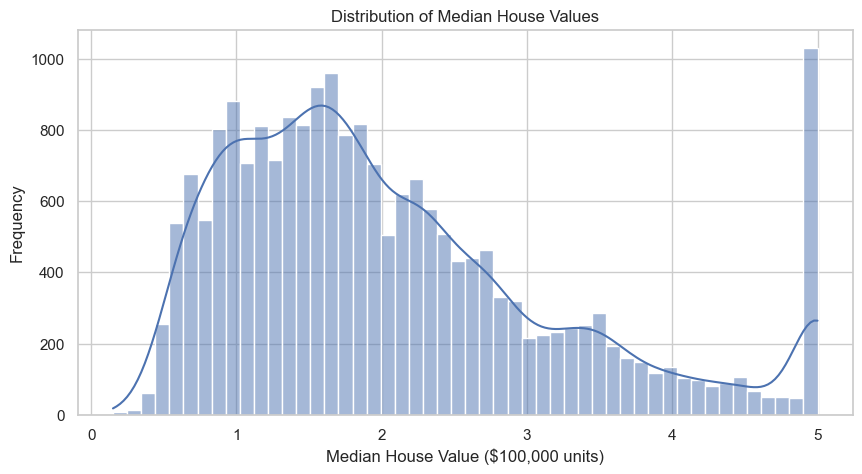

In [9]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="MedHouseVal",
    bins=50,
    kde=True
)

plt.title("Distribution of Median House Values")
plt.xlabel("Median House Value ($100,000 units)")
plt.ylabel("Frequency")

plt.show()

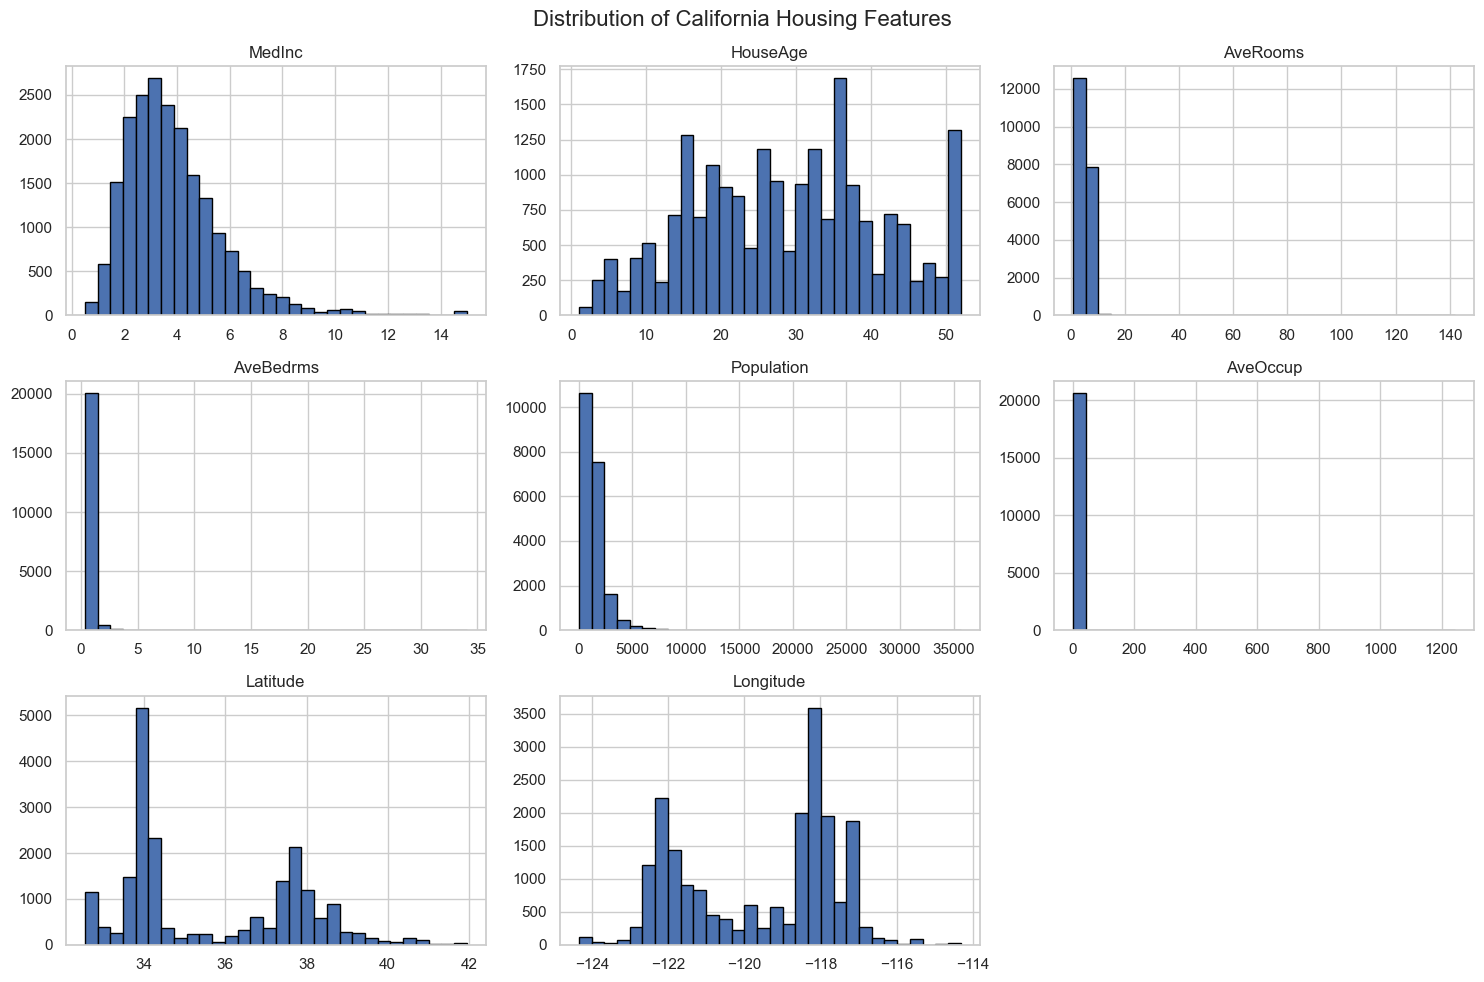

In [10]:
features = housing.feature_names

df[features].hist(
    figsize=(15, 10),
    bins=30,
    edgecolor="black"
)

plt.suptitle(
    "Distribution of California Housing Features",
    fontsize=16
)

plt.tight_layout()
plt.show()

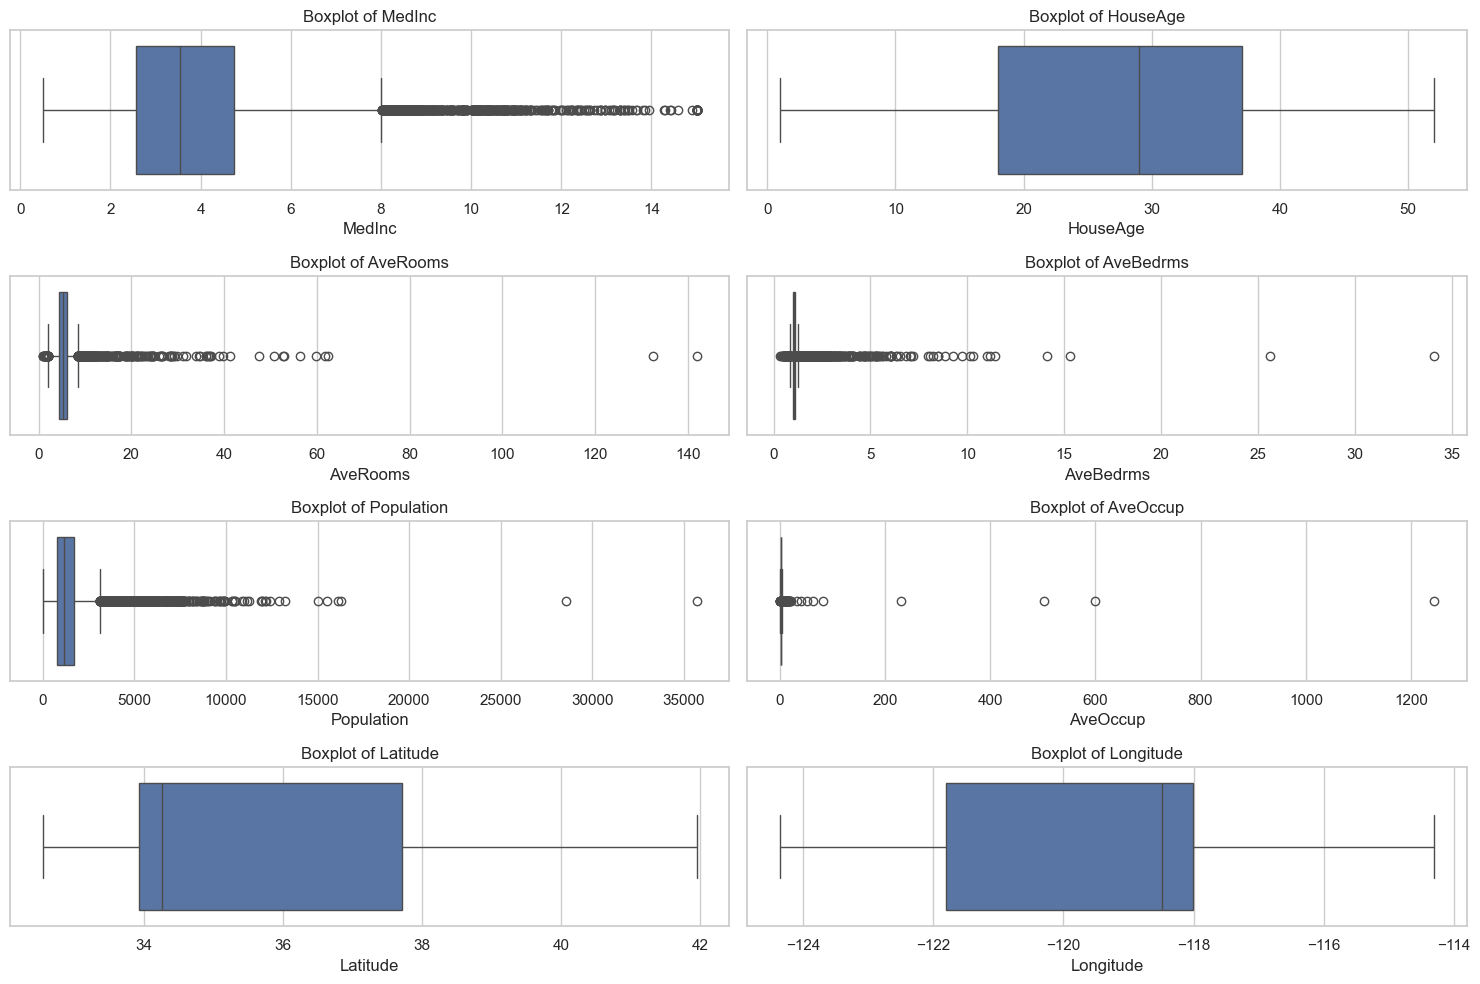

In [11]:
plt.figure(figsize=(15, 10))

for index, column in enumerate(features, 1):

    plt.subplot(4, 2, index)

    sns.boxplot(
        x=df[column]
    )

    plt.title(f"Boxplot of {column}")

plt.tight_layout()
plt.show()

In [12]:
# Independent variables (input features)
X = df[features]

# Dependent variable (target)
y = df["MedHouseVal"]

print("Input Features Shape:", X.shape)
print("Target Variable Shape:", y.shape)

display(X.head())
display(y.head())

Input Features Shape: (20640, 8)
Target Variable Shape: (20640,)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25


0    4.526
1    3.585
2    3.521
3    3.413
4    3.422
Name: MedHouseVal, dtype: float64

In [13]:
# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

# Display dataset sizes
print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Features: (16512, 8)
Testing Features: (4128, 8)
Training Target: (16512,)
Testing Target: (4128,)
